# Stock 6: a hole in the data, and the test row sits in it

For stock 6 every model fits the training data well. The hard part is that the test row sits **where there is no training data at all**, so the training score can't tell you which model to trust.

### The plan

| Part | What we do |
|---|---|
| 1 | Load and check the data |
| 2 | Look at the data and find the trap |
| 3 | Compare many models fairly, including a test of how they handle unseen x3 values |
| 4 | Does mixing models help? |
| 5 | Predict stock 6 |
| 6 | Measure how sure we are (two kinds of uncertainty) |
| 7 | Make a quote and a trading plan |

### Words used in this notebook

| Word | Meaning |
|---|---|
| **Clue** (= feature) | One column of the data, `x1` to `x5`. |
| **The gap** | The empty range of `x3` between 10 and 34: no training row has a value there. |
| **Interpolate** | Predict *between* known values. Normally safe, but not across a gap this wide. |
| **Extrapolate** | Predict *beyond* known values. Risky. |
| **CV RMSE** | How many pounds the model is wrong by on rows it hasn't seen, *picked at random*. |
| **Edge test** | Train only on the outer parts of each x3 cluster and test on the inner parts, which the model has never seen. It measures how well a model reaches into unseen x3 territory. |
| **Concave** | A curve that bends downwards, like an arch. |

Run the cells from top to bottom (or **Restart**, then **Run All**). Part 3 takes about 10 minutes.

---
# Part 1: Load and check the data

### Step 1.1: Load the tools

In [1]:
import warnings
warnings.filterwarnings("ignore")          # hide harmless library warnings so the output stays readable

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from scipy.optimize import nnls

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, PolynomialFeatures
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, HuberRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

pd.set_option("display.max_colwidth", None)    # show long text in tables in full, without "..."
print("All tools loaded.")

All tools loaded.


### Step 1.2: Open the data files

In [2]:
DATA_DIR = Path("../datasets")     # the data folder is one level up from this notebook
if not DATA_DIR.exists():          # in case the notebook was started from the main folder instead
    DATA_DIR = Path("datasets")

train = pd.read_csv(DATA_DIR / "stock_6_train.csv")   # the examples we learn from
test = pd.read_csv(DATA_DIR / "stock_6_test.csv")     # the one row we must price


clue_columns = [c for c in train.columns if c.startswith("x")]   # x1 ... x5

print("Training data:", train.shape[0], "rows")
print("Test data:    ", test.shape[0], "row")
print("Clues:        ", len(clue_columns))
train.head()

Training data: 25000 rows
Test data:     1 row
Clues:         5


,uid,x1,x2,x3,x4,x5,price
0,776641829b,-1.4083,-1.8127,8.4375,-0.1096,-0.0018,632.10
1,a353b23bc8,-1.2089,-1.8556,39.7953,0.0903,0.1639,388.93
2,98bf1b6ddd,-0.0308,0.8217,38.2091,1.4992,-2.2410,479.61
3,18615f6b9f,0.0213,-1.4052,38.4632,1.5944,0.8064,469.25
4,222bfb7d83,-3.0443,0.3061,34.2131,1.2766,1.6645,635.32


### Step 1.3: Quick health check

In [3]:
print("Empty cells in train:", train.isna().sum().sum())
print("Empty cells in test: ", test[clue_columns].isna().sum().sum())
print("Repeated rows in train:", train[clue_columns].duplicated().sum())
print()
print(train[clue_columns + ["price"]].describe().round(2).to_string())
print("\nThe test row:")
test

Empty cells in train: 0
Empty cells in test:  0
Repeated rows in train: 0

             x1        x2        x3        x4        x5     price
count  25000.00  25000.00  25000.00  25000.00  25000.00  25000.00
mean       0.00      0.00     22.09      0.01      0.01    556.93
std        1.01      1.00     15.11      1.00      0.99     83.51
min       -3.82     -3.72      4.00     -4.23     -4.13    355.48
25%       -0.68     -0.68      7.00     -0.67     -0.67    490.84
50%        0.00     -0.00     34.03      0.01      0.02    562.14
75%        0.68      0.67     37.02      0.69      0.68    626.42
max        4.13      4.34     40.00      3.85      4.29    734.67

The test row:


,id,uid,x1,x2,x3,x4,x5
0,stock_6,62ad656a4b,0.3527,-0.4198,21.395,0.5841,-0.9066


Clean data: no empty cells, no repeats. Prices average about **£557**, and they never go above about **£735** in training. Four clues (`x1`, `x2`, `x4`, `x5`) look like ordinary bell-shaped numbers around 0. `x3` is different: it runs from 4 to 40.

> **✅ Checkpoint.** 25,000 clean rows, 5 clues, nothing missing.

---
# Part 2: Look at the data

### Step 2.1: Is the test row "normal"?

The same check as in stocks 1, 2 and 4: is each clue inside the training range, and how many std steps is it from the average?

In [4]:
test_row = test[clue_columns].iloc[0]

check = pd.DataFrame({
    "test row": test_row,
    "smallest in training": train[clue_columns].min(),
    "largest in training": train[clue_columns].max(),
    "std steps from average": ((test_row - train[clue_columns].mean()) / train[clue_columns].std()).round(2),
})
check

,test row,smallest in training,largest in training,std steps from average
x1,0.3527,-3.8188,4.1272,0.35
x2,-0.4198,-3.7238,4.3428,-0.42
x3,21.3950,4.0003,39.9993,-0.05
x4,0.5841,-4.2269,3.8529,0.58
x5,-0.9066,-4.1349,4.2907,-0.93


By this check the test row looks perfectly normal: every clue is inside the training range, and `x3` is only **0.05** std steps from its average. **This check is about to fool us.**

### Step 2.2: The trap: a hole in x3

Let's draw the values of `x3` instead of just summarising them.

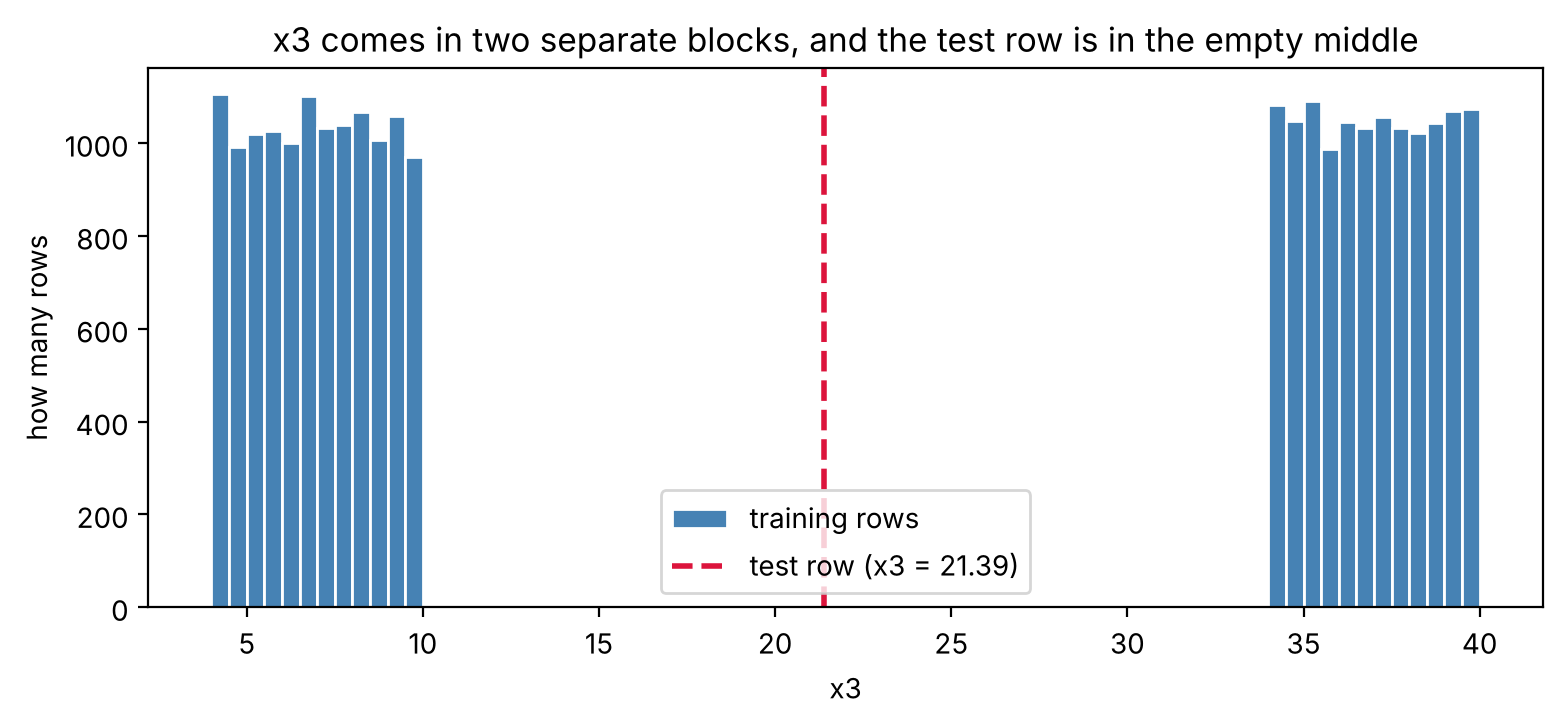

Low block:  x3 from 4.00 to 10.00  (12418 rows)
High block: x3 from 34.00 to 40.00  (12582 rows)
Training rows with x3 between 10 and 34: 0
Test row: x3 = 21.395, which is 11.4 away from the low block and 12.6 away from the high block


In [5]:
plt.figure(figsize=(9, 3.5))
plt.hist(train["x3"], bins=72, range=(4, 40), color="steelblue", edgecolor="white", label="training rows")
plt.axvline(test_row["x3"], color="crimson", linestyle="--", linewidth=2, label=f"test row (x3 = {test_row['x3']:.2f})")
plt.xlabel("x3"); plt.ylabel("how many rows")
plt.title("x3 comes in two separate blocks, and the test row is in the empty middle")
plt.legend()
plt.show()

low_block, high_block = train["x3"] < 22, train["x3"] > 22
print(f"Low block:  x3 from {train.loc[low_block, 'x3'].min():.2f} to {train.loc[low_block, 'x3'].max():.2f}  ({low_block.sum()} rows)")
print(f"High block: x3 from {train.loc[high_block, 'x3'].min():.2f} to {train.loc[high_block, 'x3'].max():.2f}  ({high_block.sum()} rows)")
print(f"Training rows with x3 between 10 and 34: {((train['x3'] > 10) & (train['x3'] < 34)).sum()}")
print(f"Test row: x3 = {test_row['x3']:.3f}, which is {test_row['x3'] - 10:.1f} away from the low block and {34 - test_row['x3']:.1f} away from the high block")

**How to read this**

* `x3` only takes values in **two blocks**: 4 to 10, and 34 to 40. **Not one** training row has `x3` between 10 and 34.
* The average of `x3` (about 22) falls in the empty middle, so the test row (21.4) looks "average". That's why the std-steps check said it was normal. **An average can sit where no data is.**
* To price the test row, a model has to guess what happens across a **24-unit gap** it has never seen. Different models will guess very differently.

### Step 2.3: How does price depend on x3?

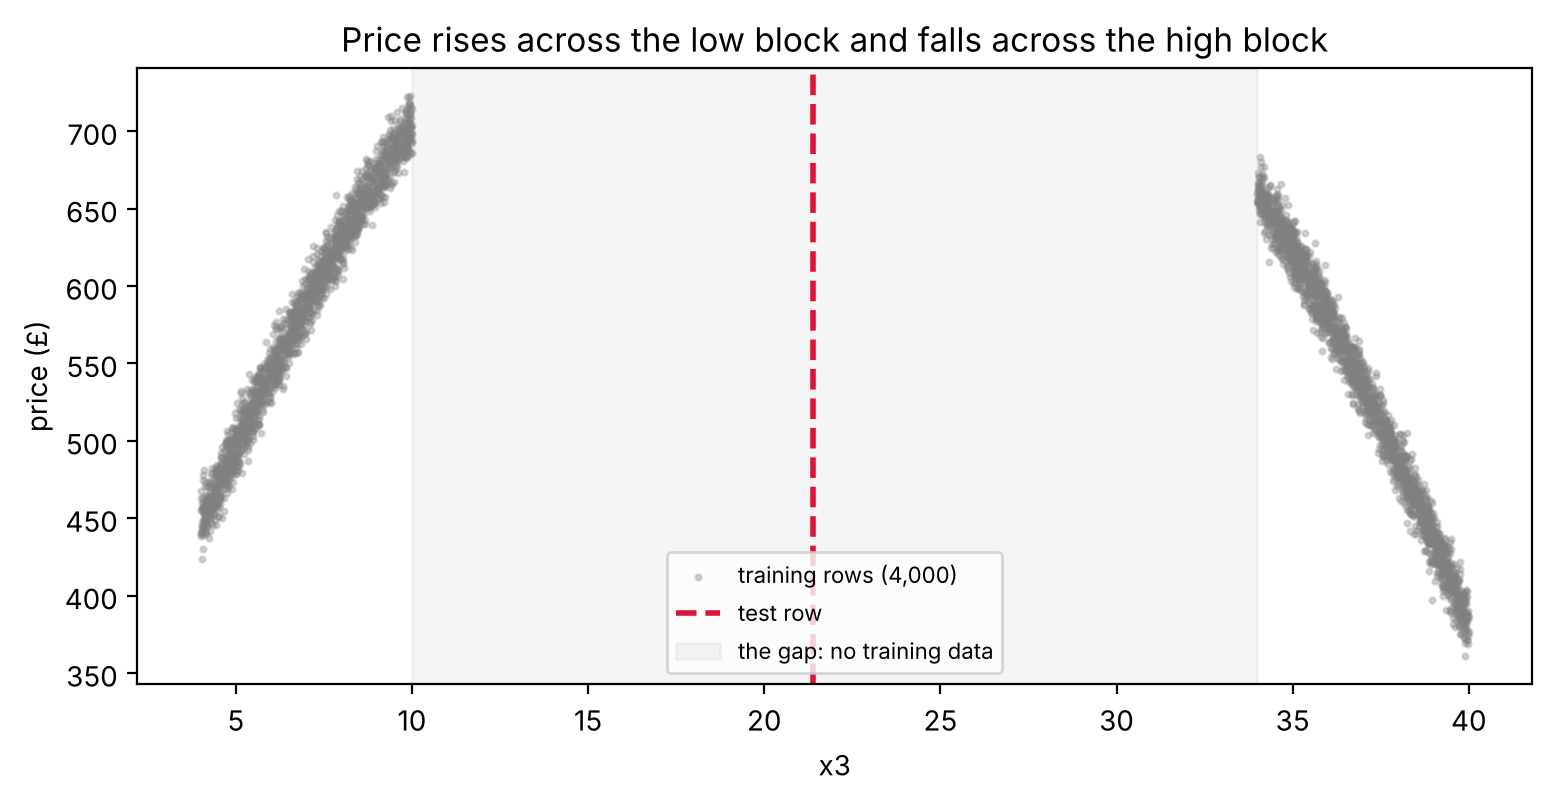

In [6]:
sample = train.sample(4000, random_state=0)

plt.figure(figsize=(9, 4))
plt.scatter(sample["x3"], sample["price"], s=4, alpha=0.3, color="grey", label="training rows (4,000)")
plt.axvline(test_row["x3"], color="crimson", linestyle="--", linewidth=2, label="test row")
plt.axvspan(10, 34, color="grey", alpha=0.08, label="the gap: no training data")
plt.xlabel("x3"); plt.ylabel("price (£)")
plt.title("Price rises across the low block and falls across the high block")
plt.legend(loc="lower center", fontsize=8)
plt.show()

* In the **low block** the price **climbs** as `x3` grows, and the climb is slowing down (the arc bends over).
* In the **high block** the price **falls** as `x3` grows, and the fall is speeding up.
* Both pieces bend **downwards**. That's what the two sides of an **arch** look like. The obvious question is whether they are two pieces of the **same** arch, with its top in the gap.

### Step 2.4: The other clues

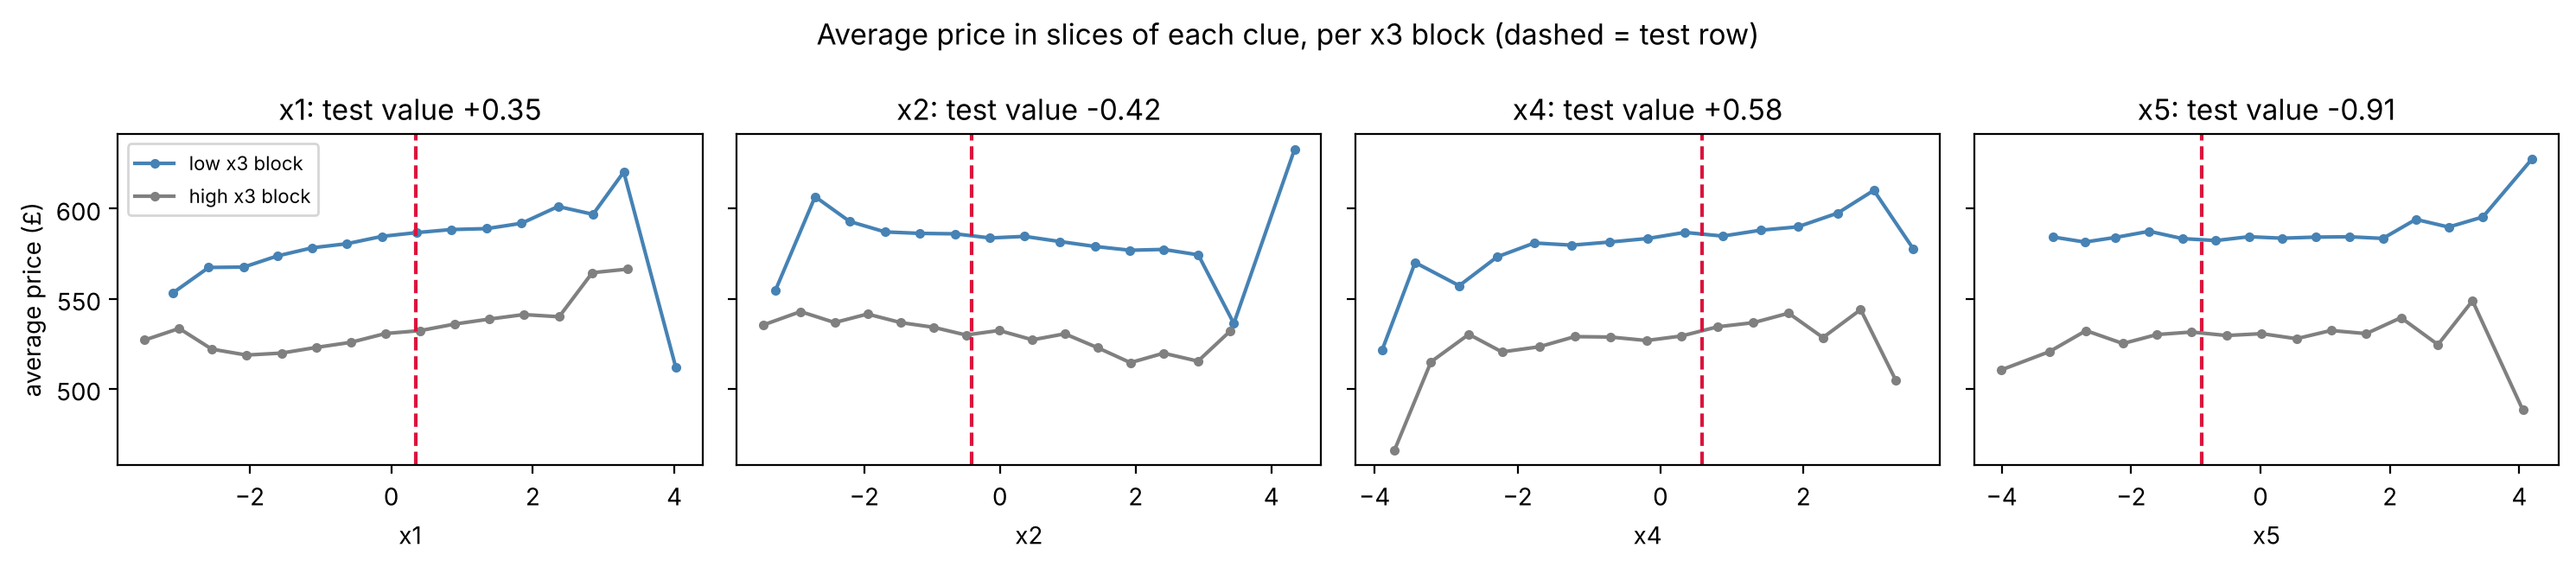

In [7]:
other_clues = ["x1", "x2", "x4", "x5"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.3), sharey=True)
for ax, clue in zip(axes, other_clues):
    for block, colour, label in [(low_block, "steelblue", "low x3 block"), (high_block, "grey", "high x3 block")]:
        part = train[block]
        slices = pd.cut(part[clue], 15)
        ax.plot(part.groupby(slices, observed=True)[clue].mean(), part.groupby(slices, observed=True)["price"].mean(),
                marker="o", markersize=3, linewidth=1.5, color=colour, label=label)
    ax.axvline(test_row[clue], color="crimson", linestyle="--", linewidth=1.5)
    ax.set_title(f"{clue}: test value {test_row[clue]:+.2f}")
    ax.set_xlabel(clue)
axes[0].set_ylabel("average price (£)")
axes[0].legend(fontsize=8)
fig.suptitle("Average price in slices of each clue, per x3 block (dashed = test row)")
plt.tight_layout()
plt.show()

Inside each block, `x1` and `x4` push the price gently **up**, `x2` gently **down**, and `x5` does nothing. The two blocks show the same slopes, just at different heights. These clues matter much less than `x3`.

### Step 2.5: One arch or two? Fit each block on its own

If the two blocks are pieces of the same arch (a **parabola**: price = start + b × x3 + c × x3²), then fitting a parabola to **each block separately** should give **the same** curve, even though the two blocks share no rows.

In [8]:
def parabola_clues(d):
    # x1, x2, x4, x5 as they are, plus x3 and x3 squared
    return np.column_stack([d["x1"], d["x2"], d["x4"], d["x5"], d["x3"], d["x3"] ** 2])

rows = []
block_models = {}
for name, block in [("low block only (x3 4–10)", low_block), ("high block only (x3 34–40)", high_block)]:
    m = LinearRegression().fit(parabola_clues(train[block]), train.loc[block, "price"])
    block_models[name] = m
    b, c = m.coef_[4], m.coef_[5]
    rows.append({"fitted on": name, "x1": m.coef_[0], "x2": m.coef_[1], "x4": m.coef_[2], "x5": m.coef_[3],
                 "x3": b, "x3²": c, "top of the arch at x3 =": -b / (2 * c),
                 "price at test row (£)": m.predict(parabola_clues(test))[0]})
pd.DataFrame(rows).round(3)

,fitted on,x1,x2,x4,x5,x3,x3²,top of the arch at x3 =,price at test row (£)
0,low block only (x3 4–10),6.010,-3.925,3.101,0.012,64.153,-1.491,21.517,908.660
1,high block only (x3 34–40),5.997,-4.025,2.932,-0.062,62.710,-1.480,21.192,909.992


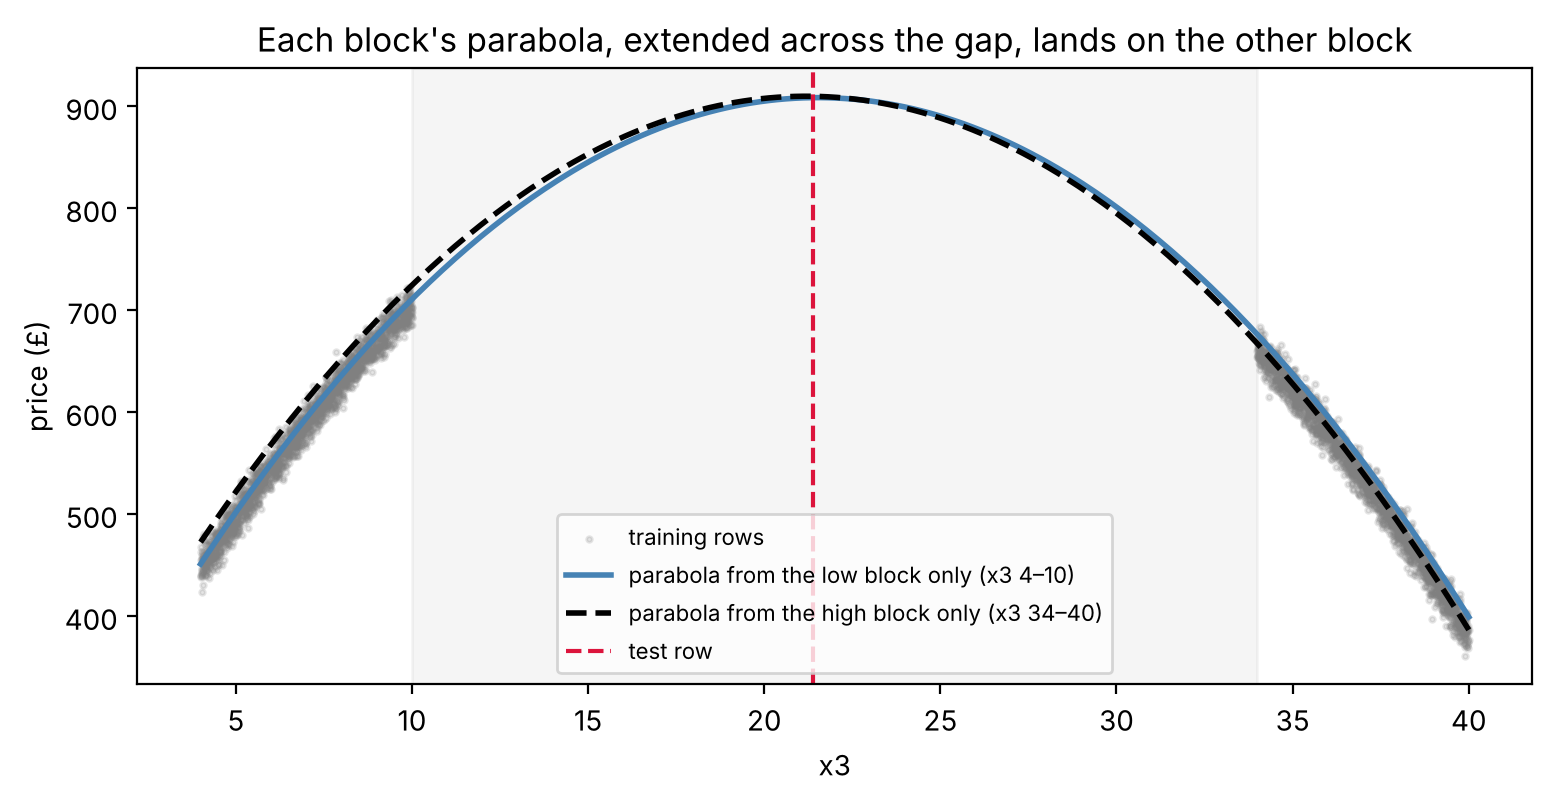

In [9]:
xs = np.linspace(4, 40, 300)
grid = pd.DataFrame({c: np.full(len(xs), test_row[c]) for c in clue_columns}); grid["x3"] = xs   # test row, x3 varied

plt.figure(figsize=(9, 4))
plt.scatter(sample["x3"], sample["price"], s=4, alpha=0.2, color="grey", label="training rows")
for (name, m), style in zip(block_models.items(), ["-", "--"]):
    plt.plot(xs, m.predict(parabola_clues(grid)), linestyle=style, linewidth=2,
             color="steelblue" if style == "-" else "black", label=f"parabola from the {name}")
plt.axvline(test_row["x3"], color="crimson", linestyle="--", linewidth=1.5, label="test row")
plt.axvspan(10, 34, color="grey", alpha=0.08)
plt.xlabel("x3"); plt.ylabel("price (£)")
plt.title("Each block's parabola, extended across the gap, lands on the other block")
plt.legend(loc="lower center", fontsize=8)
plt.show()

**How to read this**

* The two blocks share **no rows**, yet their parabolas are almost identical: bend −1.491 vs −1.480, top of the arch at **21.5 vs 21.2**, and the same small weights on `x1` (≈ 6), `x2` (≈ −4), `x4` (≈ 3) and `x5` (≈ 0).
* Extended across the gap, each block's curve lands right on top of the other block's data. Two independent pieces of evidence point to **one arch**.
* Both curves put the test row at about **£909–£910**, at the very **top** of the arch. That's about **£175 above the highest price in the whole training data** (£735).

> **✅ Checkpoint.** Stock 6's trap: the test row looks average but sits in a **24-unit hole** in `x3`, right where the arch peaks. Any model that can't extend a curve across the hole will be badly wrong.

---
# Part 3: Compare models fairly

### Step 3.1: Two tests

1. **Ordinary 5-fold CV** (rows picked at random). Every test row has training neighbours with almost the same `x3`. It measures how well a model **copies the pattern where data exists**.
2. **The edge test.** This copies our real problem on a smaller scale. We train **only** on `x3` in 4–7 and 37–40, and test on `x3` in 7–10 and 34–37. The model has never seen those `x3` values and must **reach into the unknown** by up to 3 units. (The real test row is 11–13 units in, so this is a gentle version.)

For each model we pick the settings by ordinary CV (what most teams will do), then run the edge test with those settings.

In [10]:
X = train[clue_columns]          # the clues
y = train["price"]               # the answers
X_test = test[clue_columns]      # the test row's clues

cv = KFold(n_splits=5, shuffle=True, random_state=0)   # 5 fair tests (25,000 rows: one round is stable)

edge_learn = (X["x3"] <= 7) | (X["x3"] >= 37)          # outer parts of each block
edge_check = ~edge_learn                                 # inner parts: x3 values the model never sees
print("Edge test: learn on", edge_learn.sum(), "rows, check on", edge_check.sum(), "rows")

def edge_test_rmse(model):
    # train a fresh copy on the outer parts only, then measure the error on the inner parts
    m = clone(model).fit(X[edge_learn], y[edge_learn])
    return np.sqrt(np.mean((y[edge_check] - m.predict(X[edge_check])) ** 2))

Edge test: learn on 12545 rows, check on 12455 rows


### Step 3.2: The models and their settings

Same contest as stock 4, on the raw clues `x1`–`x5`.

**Group A, GridSearchCV:** linear regression, Ridge, Lasso, ElasticNet, Huber, random forest, SVR, MLP.
**Group B, RandomizedSearchCV (10 random combinations each):** XGBoost, LightGBM, CatBoost.

In [11]:
grid_models = {
    "Linear regression": (LinearRegression(), {}),
    "Ridge": (Ridge(), {"model__alpha": np.logspace(-2, 3, 6)}),
    "Lasso": (Lasso(max_iter=20000), {"model__alpha": np.logspace(-3, 0, 6)}),
    "ElasticNet": (ElasticNet(max_iter=20000), {"model__alpha": np.logspace(-3, 0, 4),
                                                "model__l1_ratio": [0.2, 0.5, 0.8]}),
    "Huber": (HuberRegressor(max_iter=1000), {"model__epsilon": [1.35, 2.0, 3.0]}),
    "Random forest": (RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=1),
                      {"model__min_samples_leaf": [5, 20, 50]}),
    "SVR": (SVR(epsilon=1.0, cache_size=1000), {"model__C": [30, 300]}),
    "MLP": (MLPRegressor(max_iter=500, early_stopping=True, random_state=0),
            {"model__hidden_layer_sizes": [(64, 32), (128, 64)], "model__alpha": [1e-4, 1e-2]}),
}
random_models = {
    "XGBoost": (XGBRegressor(random_state=0, n_jobs=1),
                {"model__n_estimators": [300, 600, 1000],
                 "model__learning_rate": [0.02, 0.05, 0.1],
                 "model__max_depth": [3, 4, 6],
                 "model__min_child_weight": [1, 5, 20],
                 "model__subsample": [0.7, 0.85, 1.0],
                 "model__colsample_bytree": [0.7, 1.0],
                 "model__reg_lambda": [1, 5, 10]}),
    "LightGBM": (LGBMRegressor(random_state=0, n_jobs=1, subsample_freq=1, verbose=-1),
                 {"model__n_estimators": [300, 600, 1000],
                  "model__learning_rate": [0.02, 0.05, 0.1],
                  "model__num_leaves": [7, 15, 31],
                  "model__min_child_samples": [20, 50, 100],
                  "model__subsample": [0.7, 0.85, 1.0],
                  "model__colsample_bytree": [0.7, 1.0],
                  "model__reg_lambda": [0, 5, 10]}),
    "CatBoost": (CatBoostRegressor(random_seed=0, verbose=0, thread_count=1, allow_writing_files=False),
                 {"model__iterations": [500, 1000],
                  "model__learning_rate": [0.03, 0.06, 0.1],
                  "model__depth": [4, 6, 8],
                  "model__l2_leaf_reg": [1, 3, 10]}),
}
N_ITER = 10
print("Group A:", list(grid_models.keys()))
print("Group B:", list(random_models.keys()))

Group A: ['Linear regression', 'Ridge', 'Lasso', 'ElasticNet', 'Huber', 'Random forest', 'SVR', 'MLP']
Group B: ['XGBoost', 'LightGBM', 'CatBoost']


### Step 3.3: Run the contest

About 10 minutes.

In [12]:
results = []
searches = {}

def record(name, search):
    # save one finished search: its CV score, its edge-test score and its price for the test row
    searches[name] = search
    results.append({
        "model": name,
        "CV RMSE (£)": round(-search.best_score_, 2),
        "edge test RMSE (£)": round(edge_test_rmse(search.best_estimator_), 2),
        "test prediction (£)": round(float(np.ravel(search.predict(X_test))[0]), 2),
        "best settings": search.best_params_,
    })
    print(f"{name} done")

for name, (model, settings) in grid_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = GridSearchCV(pipe, settings, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

for name, (model, settings) in random_models.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("model", model)])
    search = RandomizedSearchCV(pipe, settings, n_iter=N_ITER, cv=cv, random_state=0,
                                scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

pd.DataFrame(results).sort_values("CV RMSE (£)").reset_index(drop=True)

Linear regression done
Ridge done


Lasso done


ElasticNet done


Huber done


Random forest done


SVR done


MLP done


XGBoost done


LightGBM done


CatBoost done


,model,CV RMSE (£),edge test RMSE (£),test prediction (£),best settings
0,LightGBM,6.20,73.30,709.15,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__num_leaves': 7, 'model__n_estimators': 600, 'model__min_child_samples': 20, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
1,CatBoost,6.28,77.19,674.65,"{'model__learning_rate': 0.03, 'model__l2_leaf_reg': 3, 'model__iterations': 1000, 'model__depth': 6}"
2,XGBoost,6.33,77.87,675.35,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
3,Random forest,6.62,68.46,708.90,{'model__min_samples_leaf': 5}
4,MLP,7.32,15.29,922.14,"{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (128, 64)}"
5,SVR,8.06,16.81,939.57,{'model__C': 300}
6,ElasticNet,78.61,140.06,563.16,"{'model__alpha': 0.01, 'model__l1_ratio': 0.8}"
7,Linear regression,78.61,140.06,563.18,{}
8,Huber,78.61,140.05,563.18,{'model__epsilon': 2.0}
9,Ridge,78.61,140.05,563.15,{'model__alpha': 100.0}


**What this shows**

* **Ordinary CV can't see the problem.** The tree models (LightGBM, CatBoost, XGBoost, random forest) score **£6.2–£6.6**, and a team that trusts CV will feel very confident in them.
* **The edge test can.** Asked to reach just 3 units into unseen `x3`, the tree models are off by **£68–£78**. A tree can only predict values it has seen, so beyond the data it goes **flat**. For the test row they say **£675–£709**: wherever they happened to cut the gap, never more than the training prices.
* MLP and SVR bend smoothly, so they do better on the edge test (£15–£17) and price the test row at **£922–£940**: closer to the arch, but not built to follow it.
* The straight-line models (linear regression, Ridge, Lasso, ElasticNet, Huber) miss the arch completely: £79 on CV, £140 on the edge test, about **£563** for the test row.

### Step 3.4: Use what we learned in Part 2

| Model | What it is |
|---|---|
| Parabola line | Linear regression on `x1`, `x2`, `x4`, `x5`, `x3`, `x3²`: the shape from Step 2.5 |
| Parabola + x3³ | Adds `x3³`. A check: does the arch lean to one side? |
| Polynomial (degree 2), all clues | Every square and pair of `x1`–`x5`, with a little Ridge shrinkage. A generic approach some teams will try |
| Polynomial (degree 3), all clues | The same with cubes |

In [13]:
def parabola_plus_cube(d):
    z = d["x3"] - 22                            # centred, so the powers stay a sensible size
    return np.column_stack([d["x1"], d["x2"], d["x4"], d["x5"], z, z ** 2, z ** 3])

extra_models = {
    "Parabola line": (Pipeline([("clues", FunctionTransformer(parabola_clues)), ("model", LinearRegression())]), {}),
    "Parabola + x3³": (Pipeline([("clues", FunctionTransformer(parabola_plus_cube)), ("model", LinearRegression())]), {}),
    "Polynomial (degree 2), all clues": (Pipeline([("poly", PolynomialFeatures(2)), ("scaler", StandardScaler()), ("model", Ridge())]),
                                         {"model__alpha": [0.1, 10]}),
    "Polynomial (degree 3), all clues": (Pipeline([("poly", PolynomialFeatures(3)), ("scaler", StandardScaler()), ("model", Ridge())]),
                                         {"model__alpha": [0.1, 10]}),
}
for name, (pipe, settings) in extra_models.items():
    search = GridSearchCV(pipe, settings, cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
    search.fit(X, y)
    record(name, search)

results_table = pd.DataFrame(results).sort_values("edge test RMSE (£)").reset_index(drop=True)
results_table

Parabola line done
Parabola + x3³ done


Polynomial (degree 2), all clues done


Polynomial (degree 3), all clues done


,model,CV RMSE (£),edge test RMSE (£),test prediction (£),best settings
0,Parabola + x3³,6.02,5.98,905.75,{}
1,Parabola line,6.02,5.98,905.73,{}
2,"Polynomial (degree 2), all clues",6.02,6.19,905.25,{'model__alpha': 0.1}
3,"Polynomial (degree 3), all clues",6.04,6.90,905.33,{'model__alpha': 0.1}
4,MLP,7.32,15.29,922.14,"{'model__alpha': 0.0001, 'model__hidden_layer_sizes': (128, 64)}"
5,SVR,8.06,16.81,939.57,{'model__C': 300}
6,Random forest,6.62,68.46,708.90,{'model__min_samples_leaf': 5}
7,LightGBM,6.20,73.30,709.15,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__num_leaves': 7, 'model__n_estimators': 600, 'model__min_child_samples': 20, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"
8,CatBoost,6.28,77.19,674.65,"{'model__learning_rate': 0.03, 'model__l2_leaf_reg': 3, 'model__iterations': 1000, 'model__depth': 6}"
9,XGBoost,6.33,77.87,675.35,"{'model__subsample': 0.85, 'model__reg_lambda': 10, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}"


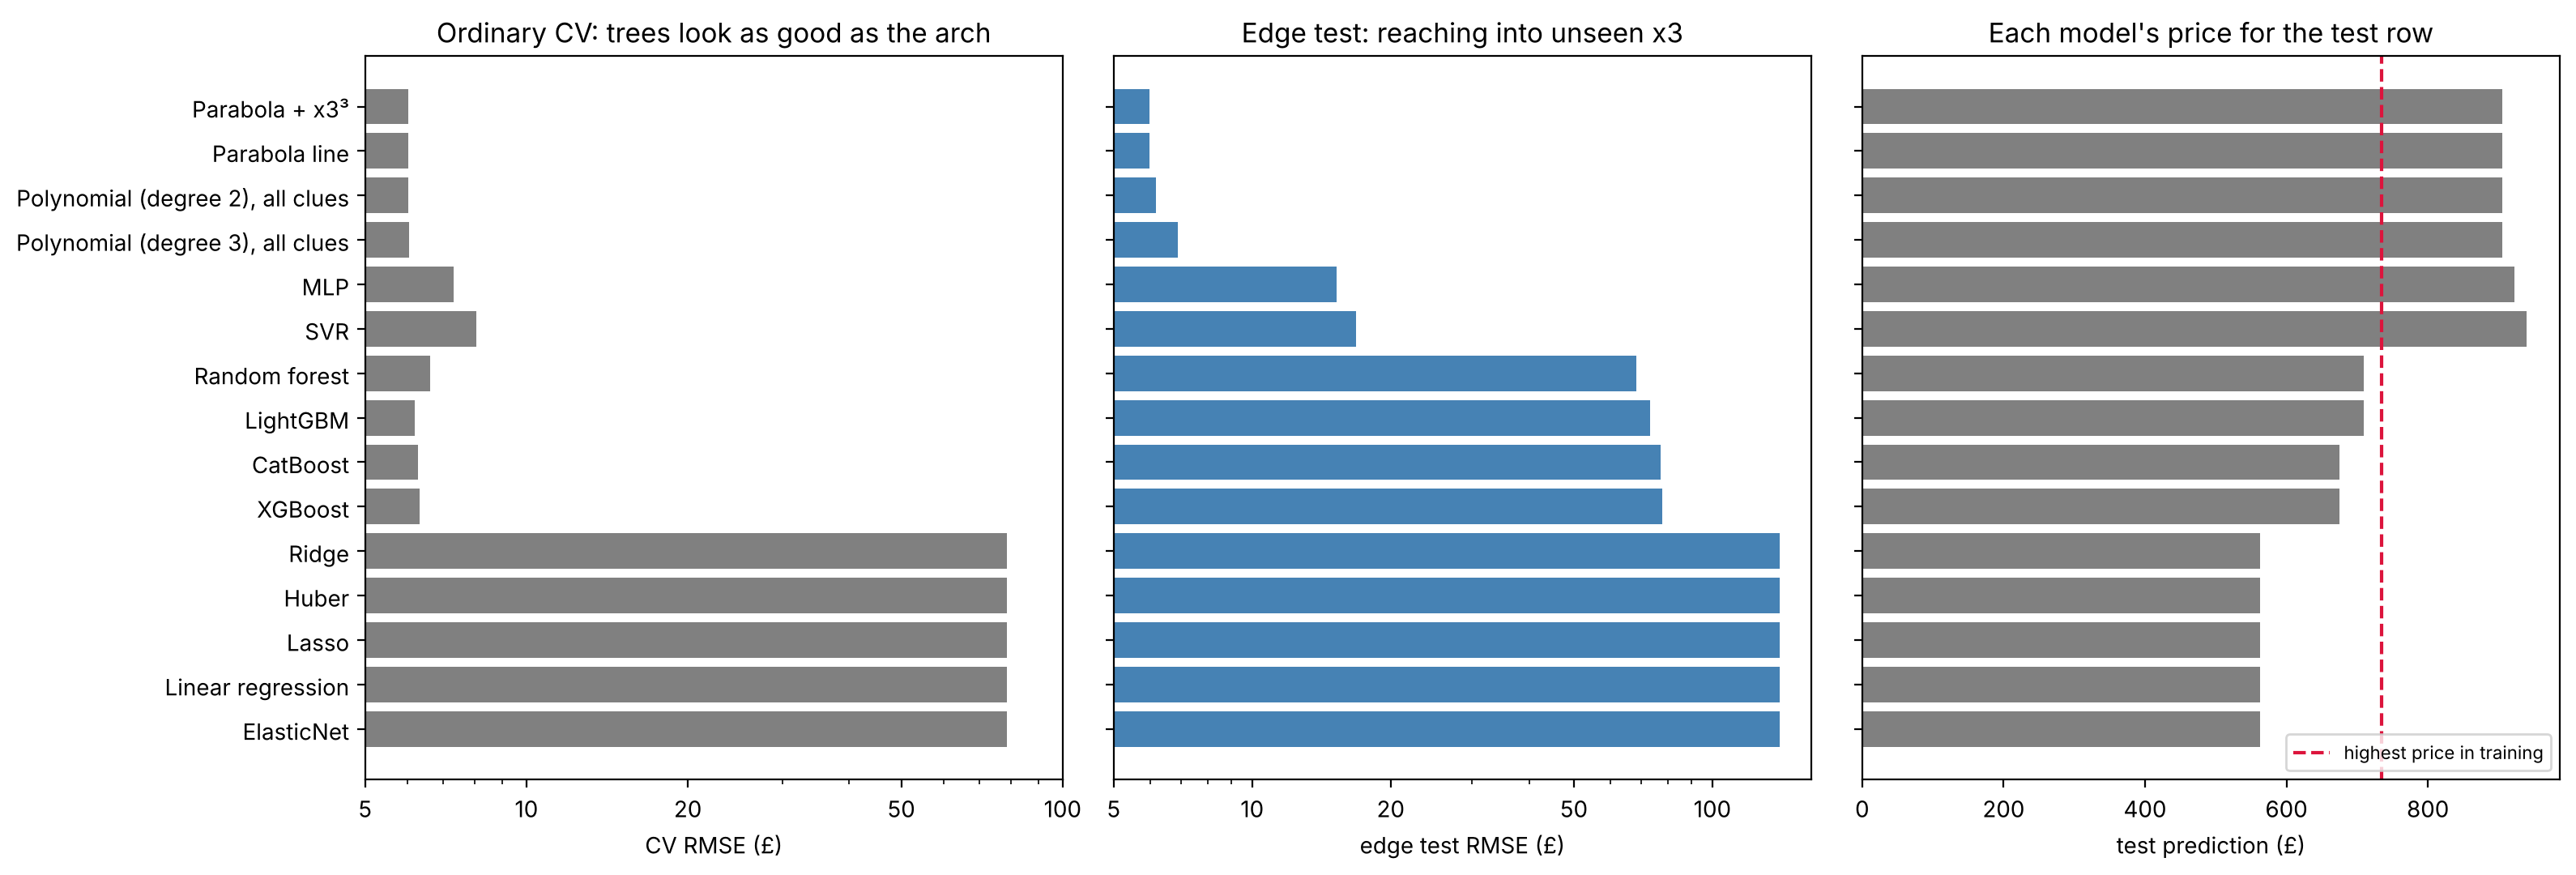

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
for ax, column, colour, title in [
        (axes[0], "CV RMSE (£)", "grey", "Ordinary CV: trees look as good as the arch"),
        (axes[1], "edge test RMSE (£)", "steelblue", "Edge test: reaching into unseen x3"),
        (axes[2], "test prediction (£)", "grey", "Each model's price for the test row")]:
    ax.barh(results_table["model"], results_table[column], color=colour)
    ax.set_xlabel(column); ax.set_title(title)
axes[0].set_xscale("log"); axes[1].set_xscale("log")
for ax in axes[:2]:
    ax.set_xticks([5, 10, 20, 50, 100]); ax.set_xticklabels(["5", "10", "20", "50", "100"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
axes[2].axvline(train["price"].max(), color="crimson", linestyle="--", linewidth=1.5, label="highest price in training")
axes[2].legend(fontsize=8, loc="lower right")
axes[0].invert_yaxis()                                        # best edge-test model at the top
plt.tight_layout()
plt.show()

**What this shows**

* The **parabola line** has the best ordinary CV (£6.02) **and** the best edge test (£5.98). Its edge-test error equals the noise: reaching 3 units into unseen `x3` costs it nothing, exactly what we'd expect if the arch is the true shape.
* Adding `x3³` changes nothing (£905.75 vs £905.73): the arch doesn't lean to one side.
* The generic polynomials (degree 2 and 3 on all clues) also find the arch (£905.3), with slightly worse edge tests because they spend effort on terms that don't matter.
* **Every model that captures the arch prices the test row at £905–£906.** Every model that doesn't gives somewhere between £563 and £940.

> **✅ Checkpoint.** On ordinary CV, trees and the arch look the same. The edge test separates them by a factor of 12. The winner is the **parabola line**.

---
# Part 4: Does mixing models help?

Normally we'd mix the best models by **ordinary CV**. Let's see what that does here. We take the 5 models with the best ordinary CV RMSE, and try:

1. a **simple average** of the top 3;
2. **learned weights** (stacking): non-negative weights fitted on the OOF predictions of all 5.

For each mix we check the ordinary CV score, the **edge test** and the **test-row price**.

In [15]:
top5 = results_table.sort_values("CV RMSE (£)")["model"].head(5).tolist()
oof, edge_pred, test_pred = {}, {}, {}
for name in top5:
    best = searches[name].best_estimator_
    oof[name] = cross_val_predict(best, X, y, cv=cv, n_jobs=-1)
    edge_pred[name] = clone(best).fit(X[edge_learn], y[edge_learn]).predict(X[edge_check])
    test_pred[name] = float(np.ravel(best.predict(X_test))[0])
    print(f"{name}: done")
oof, edge_pred = pd.DataFrame(oof), pd.DataFrame(edge_pred)
test_pred = pd.Series(test_pred)

w_stack, _ = nnls(oof.values, y.values)                       # learned non-negative weights
w_avg = np.array([1 / 3] * 3 + [0] * (len(top5) - 3))         # simple average of the top 3
rmse = lambda truth, pred: np.sqrt(np.mean((truth - pred) ** 2))

blend_rows = []
for name, w in [("simple average of top 3", w_avg), ("learned weights (stacking)", w_stack)]:
    blend_rows.append({"mix": name, "CV RMSE (£)": rmse(y, oof.values @ w),
                       "edge test RMSE (£)": rmse(y[edge_check].values, edge_pred.values @ w),
                       "test prediction (£)": test_pred.values @ w})
for name in top5:
    blend_rows.append({"mix": f"single: {name}", "CV RMSE (£)": rmse(y, oof[name]),
                       "edge test RMSE (£)": rmse(y[edge_check].values, edge_pred[name]),
                       "test prediction (£)": test_pred[name]})
print("Top 5 by ordinary CV:", top5)
print("Learned weights:", dict(zip(top5, w_stack.round(2))))
pd.DataFrame(blend_rows).round(2)

Parabola + x3³: done
Parabola line: done
Polynomial (degree 2), all clues: done


Polynomial (degree 3), all clues: done


LightGBM: done
Top 5 by ordinary CV: ['Parabola + x3³', 'Parabola line', 'Polynomial (degree 2), all clues', 'Polynomial (degree 3), all clues', 'LightGBM']
Learned weights: {'Parabola + x3³': np.float64(0.71), 'Parabola line': np.float64(0.0), 'Polynomial (degree 2), all clues': np.float64(0.29), 'Polynomial (degree 3), all clues': np.float64(0.0), 'LightGBM': np.float64(0.0)}


,mix,CV RMSE (£),edge test RMSE (£),test prediction (£)
0,simple average of top 3,6.02,6.02,905.57
1,learned weights (stacking),6.02,6.01,905.61
2,single: Parabola + x3³,6.02,5.98,905.75
3,single: Parabola line,6.02,5.98,905.73
4,"single: Polynomial (degree 2), all clues",6.02,6.19,905.25
5,"single: Polynomial (degree 3), all clues",6.04,6.90,905.33
6,single: LightGBM,6.20,73.30,709.15


**What this shows**

* Here mixing is harmless: the top 4 by ordinary CV are all arch models, and the learned weights (71% parabola + x3³, 29% degree-2 polynomial, 0% LightGBM) give **£905.6**, practically the same.
* **But that's only because we added the arch models in Step 3.4.** With only the standard models from Groups A and B, the top 3 by ordinary CV are LightGBM, CatBoost and XGBoost, and their average prices the test row at about **£686**. Mixing models that make the **same** mistake doesn't cancel it.
* The lesson: mixing needs a validation that tests the right thing. On this stock, ordinary CV is the wrong test.

> **✅ Checkpoint.** No mixing. The final model is the **parabola line**.

---
# Part 5: Predict stock 6

### Step 5.1: Train the final model and predict

The **parabola line**, trained on all 25,000 rows.

In [16]:
final_model = LinearRegression()
final_model.fit(parabola_clues(X), y)                 # learn from all 25,000 rows

prediction = final_model.predict(parabola_clues(X_test))[0]
print(f"Predicted price of stock 6: £{prediction:.2f}")

Predicted price of stock 6: £905.73


### Step 5.2: No magic, just arithmetic

A parabola is easier to read written around its **top**: price = top height − bend × (x3 − top position)² + the small clues. We convert the fitted weights into that form.

In [17]:
w1, w2, w4, w5, b, c = final_model.coef_
top_x3 = -b / (2 * c)                                  # where the arch peaks
top_height = final_model.intercept_ - b ** 2 / (4 * c)  # price at the peak when the small clues are 0
print(f"price ≈ {top_height:.2f} {c:+.4f} × (x3 − {top_x3:.3f})² {w1:+.2f} × x1 {w2:+.2f} × x2 {w4:+.2f} × x4 {w5:+.2f} × x5\n")

t = test_row
pieces = [("top of the arch", top_height, None),
          (f"bend: {c:.4f} × (x3 − {top_x3:.3f})²", c * (t["x3"] - top_x3) ** 2, t["x3"]),
          (f"{w1:+.2f} × x1", w1 * t["x1"], t["x1"]), (f"{w2:+.2f} × x2", w2 * t["x2"], t["x2"]),
          (f"{w4:+.2f} × x4", w4 * t["x4"], t["x4"]), (f"{w5:+.2f} × x5", w5 * t["x5"], t["x5"])]
total = 0
for label, amount, value in pieces:
    total += amount
    shown = "" if value is None else f"(value {value:+.3f})"
    print(f"{label:38s} {shown:16s} {amount:+9.2f}")
print(f"{'= prediction':55s}{total:9.2f}")

price ≈ 900.15 -1.5009 × (x3 − 21.399)² +6.00 × x1 -3.97 × x2 +3.02 × x4 -0.03 × x5

top of the arch                                           +900.15
bend: -1.5009 × (x3 − 21.399)²         (value +21.395)      -0.00
+6.00 × x1                             (value +0.353)       +2.12
-3.97 × x2                             (value -0.420)       +1.67
+3.02 × x4                             (value +0.584)       +1.76
-0.03 × x5                             (value -0.907)       +0.02
= prediction                                              905.73


The test row's `x3` (21.395) is **0.004** from the top of the arch (21.399), so the bend costs nothing: the price is simply the **top height (£900.15)** plus about £6 from the small clues.

Look at the numbers again: **900, −1.50, 21.40, 6, −4, 3, 0**. These look like the organisers' recipe.

> **✅ Checkpoint.** Our best guess is **£905.73**.

---
# Part 6: How sure are we?

This time there are **two different kinds** of uncertainty.

### Step 6.1: Uncertainty if the arch is real

If the parabola really continues through the gap, the only uncertainty is the noise plus how much the fitted curve wobbles. We measure both, as in stock 4: the **OOF errors** of the parabola line (bell-shaped?) and a **bootstrap** of the test-row price.

In [18]:
oof_parabola = cross_val_predict(Pipeline([("clues", FunctionTransformer(parabola_clues)), ("model", LinearRegression())]), X, y, cv=cv)
e = y - oof_parabola
print(f"OOF errors of the parabola line: typical size (std) £{e.std():.2f}, average £{e.mean():+.2f}")
print(f"Within ±1 std: {np.mean(np.abs(e) < e.std()):.0%} (bell shape: 68%)   within ±2 std: {np.mean(np.abs(e) < 2 * e.std()):.0%} (bell shape: 95%)")
print(f"Same size in both blocks? low £{e[low_block].std():.2f}, high £{e[high_block].std():.2f}")

rng = np.random.default_rng(1)
boot = []
for b_ in range(500):
    rows_b = rng.integers(0, len(X), len(X))
    m = LinearRegression().fit(parabola_clues(X.iloc[rows_b]), y.iloc[rows_b])
    boot.append(m.predict(parabola_clues(X_test))[0])
boot = np.array(boot)
print(f"Bootstrap of the test-row price: average £{boot.mean():.2f}, wobble (std) £{boot.std():.2f}")

sigma = np.sqrt(e.std() ** 2 + boot.std() ** 2)
print(f"\nIf the arch is real: σ ≈ £{sigma:.2f}")

OOF errors of the parabola line: typical size (std) £6.02, average £-0.00
Within ±1 std: 68% (bell shape: 68%)   within ±2 std: 96% (bell shape: 95%)
Same size in both blocks? low £6.02, high £6.02


Bootstrap of the test-row price: average £905.73, wobble (std) £0.17

If the arch is real: σ ≈ £6.02


* The errors are about **£6.02** in both blocks, centred on zero and bell-shaped (68% within ±1 std, 96% within ±2).
* The bootstrap wobble at the test row is only **£0.17**: with 25,000 rows, the arch is pinned down very precisely, even 11 units into the gap.
* So **if the arch is real**, σ ≈ **£6**, and a quote of about ±£6 would be honest.

But that "if" is doing a lot of work.

### Step 6.2: Uncertainty about the gap itself

No data can tell us what happens **inside** the gap. Any curve that matches the two blocks fits the training data equally well. So instead of one number, we ask: **what range of prices is realistic?**

We assume only that the curve keeps bending **downwards** (concave) across the gap, as it does on both sides. Then there are two extreme cases:

* **Lowest:** a straight bridge from the inner edge of the low block (x3 = 10) to the inner edge of the high block (x3 = 34).
* **Highest:** a "tent": keep going in a straight line at each edge's slope until the two lines meet. No downward-bending curve can go higher than that.

All curves below use the test row's values for `x1`, `x2`, `x4` and `x5`.

In [19]:
def like_test_row(x3_values):
    # copies of the test row, with x3 replaced by each value in x3_values
    d = pd.DataFrame({c: np.full(len(x3_values), test_row[c]) for c in clue_columns})
    d["x3"] = x3_values
    return d

x3_lo_edge, x3_hi_edge = train.loc[low_block, "x3"].max(), train.loc[high_block, "x3"].min()
at = lambda x3s: final_model.predict(parabola_clues(like_test_row(x3s)))                # parabola at the test row's other clues
slope = lambda x3: b + 2 * c * x3                                                          # its steepness at x3
p_lo, p_hi = at(np.array([x3_lo_edge]))[0], at(np.array([x3_hi_edge]))[0]

def bridge(x3):    # straight line between the two inner edges
    return p_lo + (p_hi - p_lo) * (x3 - x3_lo_edge) / (x3_hi_edge - x3_lo_edge)

def tent(x3):      # the steepest downward-bending curve: the two edge tangents
    return np.minimum(p_lo + slope(x3_lo_edge) * (x3 - x3_lo_edge), p_hi + slope(x3_hi_edge) * (x3 - x3_hi_edge))

tree_name = results_table[results_table["model"].isin(["XGBoost", "LightGBM", "CatBoost", "Random forest"])].sort_values("CV RMSE (£)")["model"].iloc[0]
tree_model = searches[tree_name].best_estimator_
line_model = searches["Linear regression"].best_estimator_

gap_x3 = test_row["x3"]
alternatives = pd.DataFrame([
    {"what happens in the gap": "Parabola continues (our model)", "test price (£)": prediction},
    {"what happens in the gap": "Highest downward-bending curve (tent)", "test price (£)": tent(gap_x3)},
    {"what happens in the gap": "Lowest downward-bending curve (straight bridge)", "test price (£)": bridge(gap_x3)},
    {"what happens in the gap": f"Flat, as a tree model assumes ({tree_name})", "test price (£)": float(tree_model.predict(X_test)[0])},
    {"what happens in the gap": "One straight line through everything (linear regression)", "test price (£)": float(line_model.predict(X_test)[0])},
]).round(2)
alternatives

,what happens in the gap,test price (£)
0,Parabola continues (our model),905.73
1,Highest downward-bending curve (tent),1100.62
2,Lowest downward-bending curve (straight bridge),690.13
3,"Flat, as a tree model assumes (LightGBM)",709.15
4,One straight line through everything (linear regression),563.18


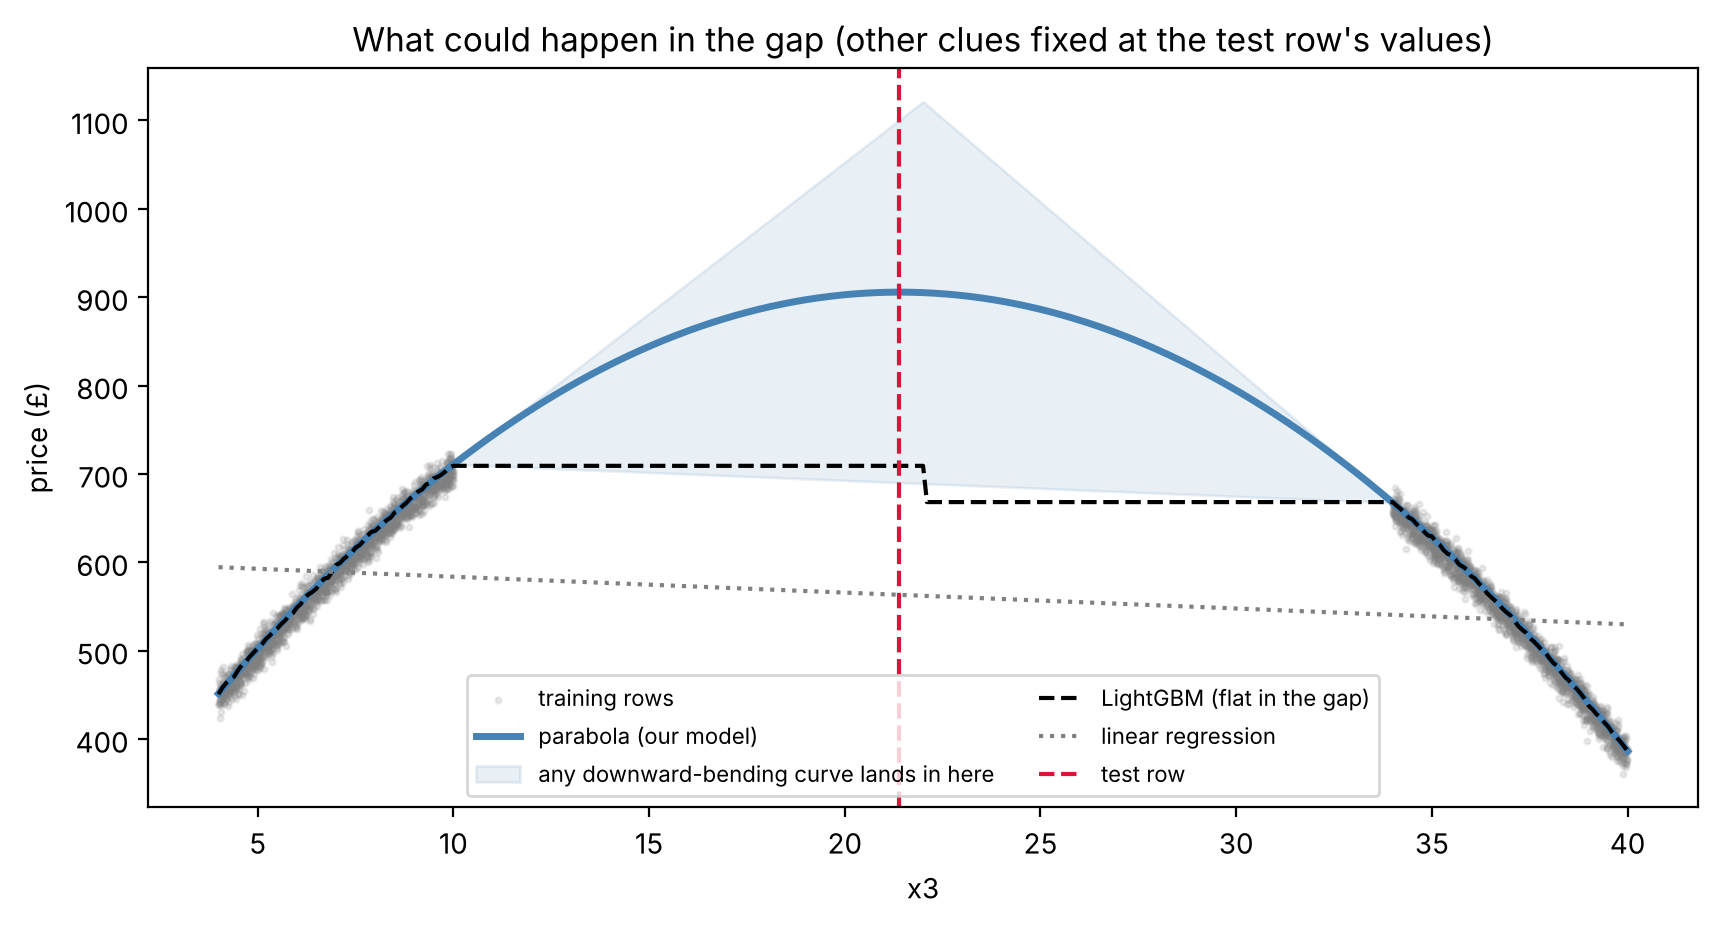

In [20]:
gx = np.linspace(4, 40, 361)
gdf = like_test_row(gx)

plt.figure(figsize=(10, 4.8))
plt.scatter(sample["x3"], sample["price"], s=4, alpha=0.15, color="grey", label="training rows")
plt.plot(gx, at(gx), color="steelblue", linewidth=2.5, label="parabola (our model)")
inside = (gx >= x3_lo_edge) & (gx <= x3_hi_edge)
plt.fill_between(gx[inside], bridge(gx[inside]), tent(gx[inside]), color="steelblue", alpha=0.12,
                 label="any downward-bending curve lands in here")
plt.plot(gx, tree_model.predict(gdf), color="black", linewidth=1.5, linestyle="--", label=f"{tree_name} (flat in the gap)")
plt.plot(gx, line_model.predict(gdf), color="grey", linewidth=1.5, linestyle=":", label="linear regression")
plt.axvline(gap_x3, color="crimson", linestyle="--", linewidth=1.5, label="test row")
plt.xlabel("x3"); plt.ylabel("price (£)")
plt.title("What could happen in the gap (other clues fixed at the test row's values)")
plt.legend(loc="lower center", fontsize=8, ncol=2)
plt.show()

**How to read this**

* The shaded area is everything a downward-bending curve could do in the gap. At the test row it runs from **£690** (straight bridge) to **£1,101** (tent). Our arch (**£906**) sits in the middle.
* The tree model is **flat** across the gap and jumps down where it happened to cut it. At the test row it says **£709** (CatBoost and XGBoost cut in a different place and say **£675**).
* Linear regression (**£563**) ignores the arch entirely.

The gap between the plausible answers (£690 to £1,101) is **about 70 times** our σ of £6.

### Step 6.3: How much do we trust the arch?

**For the arch:**
* Two blocks that share no rows independently give **the same parabola** (Step 2.5).
* The fitted numbers are suspiciously round: top height about **900**, bend **−1.50**, other weights about **6, −4, 3, 0**. All 10 stocks are synthetic, so this looks like the organisers' recipe.
* The test row's `x3` is **21.395** and the top of the arch is at **21.40**. The test row was placed **exactly at the peak**, the one spot where a tree model (flat, about £710) and the arch (about £906) disagree the most. That's very hard to explain unless the arch is what makes the price.

**Against:** we have **zero rows** in the gap. Nothing in the data can rule out the organisers doing something different there.

**Our view:** the arch is very likely right, so our best guess is **£906**. But the cost of being wrong depends on our position. Part 7 is built so that we profit if the arch is right **and** survive if it isn't.

> **✅ Checkpoint.** If the arch is real, σ ≈ £6. If it isn't, the realistic range is about **£690 to £1,101**. Never confuse the two.

---
# Part 7: Make a quote and a trading plan

### Step 7.1: Market maker or trader? Compare the two bets

Most teams will use tree models (CV RMSE about £6–7, so they feel confident) and price the stock at about **£710**. Two ways to bet on the arch:

* **A. Be the market maker** with a tight quote around £906. The tree teams then **sell** to us at our bid.
* **B. Quote wide, let a tree team be market maker** around £710, and **buy** from it.

Let's put numbers on both, in the two worlds: the arch is real (price about £906), or it isn't and the price is at the low end of the range (about £690).

In [21]:
n_tree_teams = 10           # ← how many teams you expect to price it like a tree model (change this)
their_cash = 100_000        # ← typical cash per team
my_cash = 100_000           # ← your current cash
tree_price = alternatives["test price (£)"].iloc[3]
low_end = alternatives["test price (£)"].iloc[2]

# A: we are market maker at prediction ± σ; every tree team sells us as much as it can at our bid
bid_A = prediction - sigma
shares_A = n_tree_teams * min(their_cash, 250_000) / bid_A
# B: a tree team is market maker at about tree_price ± σ; we buy as much as we can at its ask
ask_B = tree_price + sigma
shares_B = min(my_cash, 250_000) / ask_B

bets = pd.DataFrame([
    {"bet": "A: we are market maker, tight", "shares": round(shares_A),
     "profit if arch is real (£)": shares_A * (prediction - bid_A), "profit if price is at the low end (£)": shares_A * (low_end - bid_A)},
    {"bet": "B: we buy from a tree market maker", "shares": round(shares_B),
     "profit if arch is real (£)": shares_B * (prediction - ask_B), "profit if price is at the low end (£)": shares_B * (low_end - ask_B)},
]).round(0)
bets

,bet,shares,profit if arch is real (£),profit if price is at the low end (£)
0,"A: we are market maker, tight",1111,6694.0,-232936.0
1,B: we buy from a tree market maker,140,26644.0,-3502.0


**What this shows**

* **Bet A** (be market maker): if the arch is real we make about **£6.7k**. If it isn't, we lose about **£233k**, more than everything we have, and we're **eliminated**. The tree teams sell to us in size precisely when they're right.
* **Bet B** (buy from a tree market maker): if the arch is real we make about **£26.6k**. If it isn't, we lose about **£3.5k**.
* Bet B wins **in both worlds**: four times the upside, a fraction of the downside. This is the guide's advice in numbers: *"If you are unsure about a stock, a deliberately wide quote ... is a perfectly good choice: you then play as a trader."*

**Decision: we do not want to be market maker on stock 6.**

### Step 7.2: Our quote

We quote **the whole realistic range**: bid at the lowest realistic price, ask at the highest.

* The spread is far too wide to win the market-maker seat, which is the point.
* If, by some fluke, nobody quotes tighter and we **do** become market maker, every realistic price is inside our quote, so traders on either side can't hurt us much.

In [22]:
my_bid = float(np.floor(bridge(gap_x3)))      # lowest realistic price, rounded down to the pound
my_ask = float(np.ceil(tent(gap_x3)))         # highest realistic price, rounded up to the pound

print("=" * 34)
print(f"  YOUR QUOTE FOR STOCK 6")
print(f"  Bid: £{my_bid:.2f}")
print(f"  Ask: £{my_ask:.2f}")
print(f"  Spread: £{my_ask - my_bid:.2f}")
print("=" * 34)
print(f"(Best guess £{prediction:.2f}: the arch.)")

  YOUR QUOTE FOR STOCK 6
  Bid: £690.00
  Ask: £1101.00
  Spread: £411.00
(Best guess £905.73: the arch.)


### Step 7.3: The trading plan

Our σ (£6) is useless for sizing trades here: the real risk is the gap. So we size each trade by comparing:

* **Upside:** what we make per share if the arch is right (best guess £906).
* **Worst case:** what we lose per share if the price is at the **far end** of the realistic range (£690 if we buy, £1,101 if we sell).

| Upside vs worst case | Size |
|---|---|
| The market maker's price is **outside** our realistic range | **Big**: all cash (≤ £250,000). Even the worst realistic case makes money |
| Upside at least 3 × worst case | **Big** |
| Upside at least 1 × worst case | **Medium**: about half |
| Some upside, but less than the worst case | **Small**: about 10% |
| Our best guess is between its bid and ask | Minimum, 10 shares, on the side our guess leans towards |

In [23]:
mm_bid = 702.00    # ← type the market maker's bid here
mm_ask = 714.00    # ← type the market maker's ask here
my_cash = 100_000  # ← your current cash
low_end, high_end = bridge(gap_x3), tent(gap_x3)

if prediction > mm_ask:
    side, price = "BUY", mm_ask
    upside, worst = prediction - mm_ask, max(mm_ask - low_end, 0)
elif prediction < mm_bid:
    side, price = "SELL", mm_bid
    upside, worst = mm_bid - prediction, max(high_end - mm_bid, 0)
else:
    side = None

if side is None:
    lean = "BUY" if prediction > (mm_bid + mm_ask) / 2 else "SELL"
    print(f"No clear edge. {lean} the minimum, 10 shares.")
else:
    max_shares = int(min(my_cash, 250_000) // price)
    if worst == 0 or upside >= 3 * worst:
        share = 1.0
    elif upside >= worst:
        share = 0.5
    else:
        share = 0.1
    n = max(10, int(share * max_shares))
    print(f"{side} {n:,} shares at £{price:.2f}.")
    print(f"  If the arch is right: about £{upside:.2f} per share, £{n * upside:,.0f} in total.")
    print(f"  Worst realistic case: about −£{worst:.2f} per share, −£{n * worst:,.0f} in total.")

BUY 140 shares at £714.00.
  If the arch is right: about £191.73 per share, £26,842 in total.
  Worst realistic case: about −£23.87 per share, −£3,341 in total.


**Likely scenarios** (test predictions from Part 3):

| Who might be market maker | Their price | What we do |
|---|---|---|
| A tree model: CatBoost / XGBoost | about £675 | Its ask is probably **below £690**, outside even our worst realistic case: **buy big** |
| A tree model: LightGBM / random forest | about £709 | **Buy big**: upside about £190 per share vs a worst case of about £25 |
| A straight-line model | about £563 | Its spread will be wide (CV RMSE £79), but if its ask is under £690: **buy big** |
| MLP / SVR | about £920–£940 | Sell only if its bid is well above £906. Usually small or minimum |
| A team that found the arch | about £906 | No edge: minimum 10 shares |

The most likely market maker is a confident tree team (CV RMSE £6), which is exactly the case where we **buy big**.

> **✅ Final checkpoint.** Best guess **£905.73** (the arch). Honest range **£690–£1,101**, because nothing in the data covers the gap. A deliberately wide quote, **£690 / £1,101**, so we stay a trader, and a plan to **buy big** from the tree teams who are likely to win the seat.

---
# Everything in one cell

The whole recipe for stock 6, at a glance.

In [24]:
STOCK = 6
train = pd.read_csv(DATA_DIR / f"stock_{STOCK}_train.csv")
test = pd.read_csv(DATA_DIR / f"stock_{STOCK}_test.csv")
make = lambda d: np.column_stack([d["x1"], d["x2"], d["x4"], d["x5"], d["x3"], d["x3"] ** 2])

# 1) x3 has a gap (10–34) and the test row is in it; both blocks fit one parabola in x3
model = LinearRegression().fit(make(train), train["price"])
centre = model.predict(make(test))[0]

# 2) realistic range if the curve keeps bending down across the gap: straight bridge (low) to tent (high)
b, c = model.coef_[4], model.coef_[5]
lo_x, hi_x = train.loc[train["x3"] < 22, "x3"].max(), train.loc[train["x3"] > 22, "x3"].min()
at_x = lambda v: model.predict(make(test.assign(x3=v)))[0]
x = test["x3"].iloc[0]
low = at_x(lo_x) + (at_x(hi_x) - at_x(lo_x)) * (x - lo_x) / (hi_x - lo_x)
high = min(at_x(lo_x) + (b + 2 * c * lo_x) * (x - lo_x), at_x(hi_x) + (b + 2 * c * hi_x) * (x - hi_x))

# 3) quote the whole range (we don't want to be market maker); trade against tree-model market makers
print(f"best guess (the arch) £{centre:.2f}, realistic range £{low:.2f} to £{high:.2f}")
print(f"quote: bid £{np.floor(low):.2f} / ask £{np.ceil(high):.2f}")

best guess (the arch) £905.73, realistic range £690.13 to £1100.62
quote: bid £690.00 / ask £1101.00
